# Uma revisão sobre sinais e sistemas

O tema da análise e do processamento de sinais é fundamental em qualquer área da ciência e da tecnologia preocupada com a medição e o sensoreamento do universo investigado. Por exemplo:

- os acelerômetros medem como a aceleração [m/s$^2$] varia com o tempo
- os microfones de medição medem como a pressão sonora [N/m$^2$] varia com o tempo
- os termômetros medem como a temperatura, [$^\circ$C] ou [K], varia com o tempo

Embora as grandezas listadas anteriormente sejam funções do tempo, também é possível distribuir sensores no espaço e avaliar como variam em função da posição. Podemos então definir um sinal mais formalmente como:


<div style="background-color: #f0f2f5; padding: 15px; text-align: justify; border-radius: 8px; margin: 0 auto; max-width: 800px;">
Sinais são funções de uma ou mais variáveis independentes, $f(x, y, z, t)$, que contêm informações sobre o comportamento ou natureza de algum $\textbf{fenômeno}$.
</div>

<br>

Por exemplo, tomemos a fotografia mostrada na Figura 1. Ela pode ser representada como uma função $f(x,y)$, na qual $x$ e $y$ são as **variáveis indepenentes** espaciais (horizontal e vertical) e a intensidade do fenômeno em si é dado pela escala contínua ($\in \mathbb{R}$) de $0.0-1.0$ representando as cores preta ($0.0$) e branca ($1.0$).

<figure style="text-align: center;">
    <img src="\..\figs\foto_fran.jpg" width="300" alt="Fotografia em PB.">
    <figcaption style="margin-top: 8px; font-style: italic; color: #555;">
        Figura 1: Um dia quase chuvoso (por Fran Drews).
    </figcaption>
</figure>

Já a Figura 2 ilustra um sinal sonoro no qual a **variável indepenente** é o tempo (t [s]) e a amplitude do fenômeno é a pressão sonora, $p(t)$, em [N/m$^2$]. 

<figure style="text-align: center;">
    <img src="\..\figs\xt_voice.png" width="400" alt="Imagem de um sinal de áudio com voz.">
    <figcaption style="margin-top: 8px; font-style: italic; color: #555;">
        Figura 2: Um sinal de voz humana: pressão sonora $\times$ tempo.
    </figcaption>
</figure>

É interessante notar que ambos os sinais apresentados nas Figuras 1 e 2 contêm informações significativas sobre os fenômenos que mensuram (ao menos aos olhos e aos ouvidos mais atentos). Por exemplo, na Figura 1, nota-se que o fenômeno em si não é, de fato, um dia chuvoso, mas apenas uma representação artística de pessoas caminhando sob uma chuva gerada por um bebedouro. Já na Figura 2, o sinal sonoro representa a frase "*Boston Symphony Hall*", que notoriamente apresenta vocábulos de maior e menor intensidade.

# 1. Notação e classificação básica

Os sinais podem ser classificados de um jeito muito básico em sinais **contínuos** e **discretos**.

## A. Sinais contínuos

Boa parte dos fenômenos que encontramos no dia a dia tem natureza contínua. Por exemplo, a variação da temperatura no tempo e no espaço é um fenômeno contínuo, no sentido de que você não vai encontrar posições ou instantes de tempo em que não seja possível obter a informação sobre o fenômeno. O mesmo vale para a pressão sonora, a aceleração ou a diferença de potencial elétrico em um circuito analógico. Vamos então representar os sinais contínuos da seguinte forma  

<div style="background-color: #f0f2f5; padding: 15px; text-align: center; border-radius: 8px; margin: 0 auto; max-width: 800px;">
    $t$ - variável independente temporal <br>     
    $x,y,z$ - variáveis independentes espaciais <br>
    $p(t)$ [N/m$^2$] - pressão em função do tempo <br>
    $v(t)$ [V] - tensão em função do tempo <br>
    $p(x, y, z, t)$ [N/m$^2$] - pressão em função do espaço 3D e do tempo <br>
    $f(x)$ [N] - força em função do espaço 1D <br>
    $T(x,y,t)$ [$^{\circ}$C] - temperatura em uma placa em função do espaço 2D e do tempo
</div>

Note a convenção de usar letras minúsculas para o sinal e de usar variáveis independentes entre parênteses.

## B. Sinais discretos

Também é muito útil representar os sinais discretos, já que boa parte dos fenômenos que medimos hoje em dia vai ser processado por um computador e, portanto, o sinal de fato analisado terá natureza discreta. Vamos então representar os sinais discretos da seguinte forma  

<div style="background-color: #f0f2f5; padding: 15px; text-align: center; border-radius: 8px; margin: 0 auto; max-width: 800px;">
    $n$, $m$, $k$ - variáveis independentes amostrais ($0, 1, \cdots, N-1$) <br>     
    $p[n]$ [N/m$^2$] - pressão em função da amostra $n$ <br>
    $p[m,n]$ [N/m$^2$] - pressão em função das amostras $n$ e $m$ 
</div>

Note a convenção de usar letras minúsculas para o sinal e de usar as variáveis independentes entre colchetes.

## C. Uma ponte entre o discreto e o contínuo

Neste ponto, é útil estabelecer uma intuição sobre como representar sinais contínuos no computador. Por ora, será apenas uma intuição, mas veremos mais consequências formais posteriormente. Vamos imaginar que desejamos medir um fenômeno contínuo $x(t)$ tomando amostras regulares separadas por um intervalo $T_s$ [s]. A este processo chamamos amostragem. No fim dele, teremos uma representação discreta de $x(t)$ dada por um sinal discreto $x[n]$, a saber

\begin{equation}
x(t) \approx x[n] =  [p[0],\ p[T_s],\ p[2T_s],\ p[3T_s],\ \cdots,\ p[(N-1)Ts]]^T.
\end{equation}

Note que $x[n]$ é um vetor com dimensão $N$ amostras contendo as informações (incompletas) sobre o fenômeno contínuo $x(t)$. Vejamos, por exemplo tal representação para o sinal contínuo


\begin{equation}
x(t) = A \cos(2\pi f t + \phi),
\end{equation}
em que $A$, $f$ e $\phi$ são os parâmetros amplitude, frequência e fase (respectivamente) do sinal contínuo cossenoidal; $t$ é a variável independente temporal.

In [1]:
import numpy as np # arrays
import matplotlib.pyplot as plt # plots
import scipy # some signals

In [2]:
Ts = 0.01 # Sampling rate
t_sampled = np.arange(start = 0, stop = 1, step = Ts) # Sampled independent variable
print("time vector {}".format(t_sampled))
print("time vector shape {}".format(t_sampled.shape))

time vector [0.   0.01 0.02 0.03 0.04 0.05 0.06 0.07 0.08 0.09 0.1  0.11 0.12 0.13
 0.14 0.15 0.16 0.17 0.18 0.19 0.2  0.21 0.22 0.23 0.24 0.25 0.26 0.27
 0.28 0.29 0.3  0.31 0.32 0.33 0.34 0.35 0.36 0.37 0.38 0.39 0.4  0.41
 0.42 0.43 0.44 0.45 0.46 0.47 0.48 0.49 0.5  0.51 0.52 0.53 0.54 0.55
 0.56 0.57 0.58 0.59 0.6  0.61 0.62 0.63 0.64 0.65 0.66 0.67 0.68 0.69
 0.7  0.71 0.72 0.73 0.74 0.75 0.76 0.77 0.78 0.79 0.8  0.81 0.82 0.83
 0.84 0.85 0.86 0.87 0.88 0.89 0.9  0.91 0.92 0.93 0.94 0.95 0.96 0.97
 0.98 0.99]
time vector shape (100,)


In [3]:
A, f, phi = 1, 2, 0
xn = A * np.cos(2 * np.pi * f * t_sampled)
print("signal vector {}".format(np.round(xn,4)))
print("signal vector shape {}".format(xn.shape))

signal vector [ 1.      0.9921  0.9686  0.9298  0.8763  0.809   0.729   0.6374  0.5358
  0.4258  0.309   0.1874  0.0628 -0.0628 -0.1874 -0.309  -0.4258 -0.5358
 -0.6374 -0.729  -0.809  -0.8763 -0.9298 -0.9686 -0.9921 -1.     -0.9921
 -0.9686 -0.9298 -0.8763 -0.809  -0.729  -0.6374 -0.5358 -0.4258 -0.309
 -0.1874 -0.0628  0.0628  0.1874  0.309   0.4258  0.5358  0.6374  0.729
  0.809   0.8763  0.9298  0.9686  0.9921  1.      0.9921  0.9686  0.9298
  0.8763  0.809   0.729   0.6374  0.5358  0.4258  0.309   0.1874  0.0628
 -0.0628 -0.1874 -0.309  -0.4258 -0.5358 -0.6374 -0.729  -0.809  -0.8763
 -0.9298 -0.9686 -0.9921 -1.     -0.9921 -0.9686 -0.9298 -0.8763 -0.809
 -0.729  -0.6374 -0.5358 -0.4258 -0.309  -0.1874 -0.0628  0.0628  0.1874
  0.309   0.4258  0.5358  0.6374  0.729   0.809   0.8763  0.9298  0.9686
  0.9921]
signal vector shape (100,)


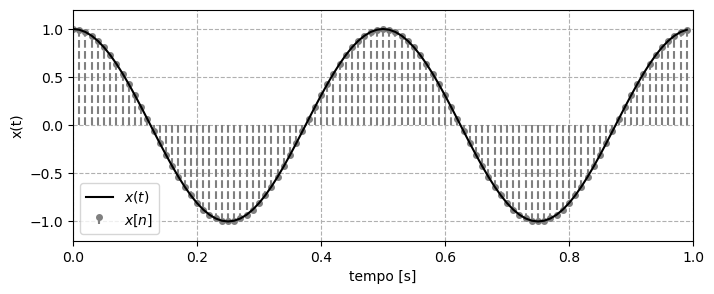

In [4]:
plt.figure(figsize = (8,3))
ml, sl, _  = plt.stem(t_sampled, xn, linefmt= 'grey',   label = r'$x[n]$', basefmt = ' ')
plt.setp(ml, markersize=4)
plt.setp(sl, linestyle='--')
plt.plot(t_sampled, xn, '-k',  label = r'$x(t)$')
plt.legend()
plt.xlim((0, 1))
plt.ylim((-1.2, 1.2))
plt.grid(linestyle = '--')
plt.xlabel('tempo [s]')
plt.ylabel('x(t)');

De forma similar, podemos pensar em amostrar o espaço. Considere o exemplo de medir a temperatura em função do espaço e do tempo ao longo de uma barra longa, sujeita a uma fonte de calor em uma de suas extremidades (Figura 3). Note que diversos sensores de temperatura foram distribuídos no espaço. 


<figure style="text-align: center;">
    <img src="\..\figs\bar_temp_sapce_time.png" width="700" alt="Imagem da medição de temperatura em uma barra.">
    <figcaption style="margin-top: 8px; font-style: italic; color: #555;">
        Figura 3: Medição discreta da temperatura em uma barra em função do tempo e do espaço: $T(x,t) \approx T[m,n]$. 
    </figcaption>
</figure>

Nossos sistemas de aquisição de dados atuais têm excelente capacidade de amostragem temporal. O período de amostragem necessário varia conforme o problema em questão. Fenômenos de variação rápida necessitarão de um período de amostragem curto. Por exemplo, para sinais de áudio, o período de amostragem tende a ser inferior a 25 [$\mu$s]. Um fenômeno como a variação de temperatura tende a ser consideravelmente mais lento.

Já a amostragem espacial ainda tende a ser um desafio, pois é preciso distribuir sensores no espaço. Isso tem um custo em termos do número de sensores e de canais de medição necessários. Uma alternativa é realizar medições sequenciais, movendo apenas 1 sensor. De qualquer forma, uma alta amostragem espacial pode se tornar proibitiva, e um compromisso será feito.

# 2. Sinais periódicos e a série de Fourier

## A. Sinais periódicos

Um sinal periódico e contínuo é um sinal que se repete dada uma translação da variável independente. Por ora, foquemos em sinais que são função do tempo. Neste caso, o sinal periódico pode ser representado matematicamente por
    
\begin{equation}
x(t) = x(t \pm mT_p),
\end{equation}
em que $T_p$ representa o período fundamental (o menor valor de tempo para o qual o sinal se repete). Assim, o valor do sinal no instante $t$ [s] é o mesmo para o instante $t \pm mT_p$ [s]. Dessa forma, o sinal se repete a cada translação de um número inteiro de períodos ($mT_p$, com $m = \pm 1, \pm 2, \ldots$).

<figure style="text-align: center;">
    <img src="\..\figs\sin_per_1.jpg" width="700" alt="Imagem de um sinal periódico.">
    <figcaption style="margin-top: 8px; font-style: italic; color: #555;">
        Figura 4: Um exemplo de uma onda quadrada, um sinal contínuo e periódico em função do tempo. 
    </figcaption>
</figure>

Os sinais periódicos têm uma frequência fundamental $f_1$ (ou frequência angular fundamental $\omega_1$) dadas por

\begin{equation}
\begin{gathered}
f_1 = \frac{1}{T_p} \ \ \text{[Hz]} \ \text{ou} \ \text{[ciclos/s]},\\
\omega_1 = \frac{2\pi}{T_p} \ \ \text{[rad/s]}.
\end{gathered}
\end{equation}

## B. Série de Fourier


A base para a estimativa do espectro de tais sinais é a ***Série de Fourier***, segundo a qual qualquer sinal periódico pode ser representado por uma soma infinita de senos e cossenos.

\begin{equation}
x(t) = \frac{a_0}{2} + \sum\limits_{k=1}^{\infty}a_k \mathrm{cos}(k \omega_1 t)+ \sum\limits_{k=1}^{\infty}b_k \mathrm{sin}(k \omega_1 t)
\tag{1}
\end{equation}
com os coeficientes dados por:

\begin{equation}
\frac{a_0}{2} = \frac{1}{T_p}\int_{T_p} x(t)\mathrm{d}t,
\tag{2}
\end{equation}

\begin{equation}
a_k = \frac{2}{T_p}\int_{T_p} x(t)\mathrm{cos}(k\omega_1t)\mathrm{d}t,
\tag{3}
\end{equation}

\begin{equation}
b_k = \frac{2}{T_p}\int_{T_p} x(t)\mathrm{sin}(k\omega_1t)\mathrm{d}t.
\tag{4}
\end{equation}

Assim, usando as Eqs. (2-4), podemos computar os coeficientes correspondentes às frequências $k\omega_1$ (múltiplos inteiros da frequência angular fundamental). Resolver 3 integrais, no entanto, é um pouco inconveniente. No entanto, usando as relações de Euler, dadas por

\begin{equation}
\begin{gathered}
\cos(k\omega_1) = \frac{\text{e}^{\text{j}k\omega_1}+\text{e}^{-\text{j}k\omega_1}}{2},\\
\sin(k\omega_1) = \frac{\text{e}^{\text{j}k\omega_1}-\text{e}^{-\text{j}k\omega_1}}{2\text{j}},
\end{gathered}
\tag{5}
\end{equation}
chegamos à representação complexa da série de Fourier, dada por

\begin{equation}
x(t) = \sum\limits_{k=-\infty}^{\infty}\tilde{c}_k \mathrm{e}^{\mathrm{j}k \omega_1 t},
\tag{6}
\end{equation}
com os coeficientes dados por:

\begin{equation}
\tilde{c}_k = \frac{1}{T_p}\int_{T_p} x(t)\mathrm{e}^{-\mathrm{j}k\omega_1 t}\mathrm{d}t.
\tag{7}
\end{equation}

### Um sinal no domínio do tempo

Vamos investigar o caso de uma onda quadrada. A equação que gera 1 período do sinal é dada por

\begin{equation}
x(t) = 
\begin{cases}
-1 \ \ \ \text{para} \ \ \ -\frac{T_p}{2} \leq t \ < 0 \\
+1 \ \ \ \text{para} \ \ \ \ \ \ 0 \leq t < -\frac{T_p}{2}
\end{cases}
\end{equation}
com $x(t) = x(t \pm mT_p)$.

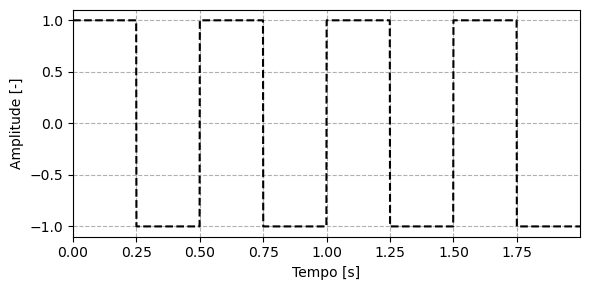

In [5]:
Ts = 0.001
t = np.arange(0, 2, Ts) # vetor temporal
f1 = 2.0 # Frequencia fundamental
w1 = 2*np.pi*f1

# onda quadrada
xt = scipy.signal.square(2 * np.pi * f1 * t)
# Figura
plt.figure(figsize = (6,3))
plt.plot(t, xt, '--k', linewidth = 1.5)
plt.grid(linestyle = '--', which='both')
plt.xlabel('Tempo [s]')
plt.ylabel('Amplitude [-]')
plt.xlim((0, t[-1]))
plt.tight_layout()
plt.show()

### o sinal no domínio da frequência

Os coeficientes, $\tilde{c}_k$ são calculados pela Eq. (7). Para este caso particular teremos

\begin{equation}
\tilde{c}_k = \frac{-\text{j}}{\pi k}[1-\cos(\pi k)],
\end{equation}
para $k = \ldots, -2, -1, 0, 1, 2, \ldots$ \& $\omega_k = \ldots, -2\omega_1, -\omega_1, 0, \omega_1, 2\omega_1, \ldots$

In [6]:
max_k = 11 # valor máximo de harmônicas
k = np.arange(-max_k, max_k+1)
freq_vec = k*f1 # vetor de frequências (proporcional a f1)
ck = (-1j/(np.pi*k))*(1-np.cos(k*np.pi)) # coeficientes de Fourier
ck[(k%2)==0] = 0 # Para calcular com os arredondamentos corretos
print("Valores de k: {}".format(k))
print("Valores de freq: {} Hz".format(freq_vec))
print("Valores de ck: {} Hz".format(ck))

Valores de k: [-11 -10  -9  -8  -7  -6  -5  -4  -3  -2  -1   0   1   2   3   4   5   6
   7   8   9  10  11]
Valores de freq: [-22. -20. -18. -16. -14. -12. -10.  -8.  -6.  -4.  -2.   0.   2.   4.
   6.   8.  10.  12.  14.  16.  18.  20.  22.] Hz
Valores de ck: [-0.+0.05787452j  0.+0.j         -0.+0.07073553j  0.+0.j
 -0.+0.09094568j  0.+0.j         -0.+0.12732395j  0.+0.j
 -0.+0.21220659j  0.+0.j         -0.+0.63661977j  0.+0.j
  0.-0.63661977j  0.+0.j          0.-0.21220659j  0.+0.j
  0.-0.12732395j  0.+0.j          0.-0.09094568j  0.+0.j
  0.-0.07073553j  0.+0.j          0.-0.05787452j] Hz


C:\Users\Win11\AppData\Local\Temp\ipykernel_3716\2452950479.py:4: RuntimeWarning: divide by zero encountered in divide
  ck = (-1j/(np.pi*k))*(1-np.cos(k*np.pi)) # coeficientes de Fourier
C:\Users\Win11\AppData\Local\Temp\ipykernel_3716\2452950479.py:4: RuntimeWarning: invalid value encountered in divide
  ck = (-1j/(np.pi*k))*(1-np.cos(k*np.pi)) # coeficientes de Fourier
C:\Users\Win11\AppData\Local\Temp\ipykernel_3716\2452950479.py:4: RuntimeWarning: invalid value encountered in multiply
  ck = (-1j/(np.pi*k))*(1-np.cos(k*np.pi)) # coeficientes de Fourier


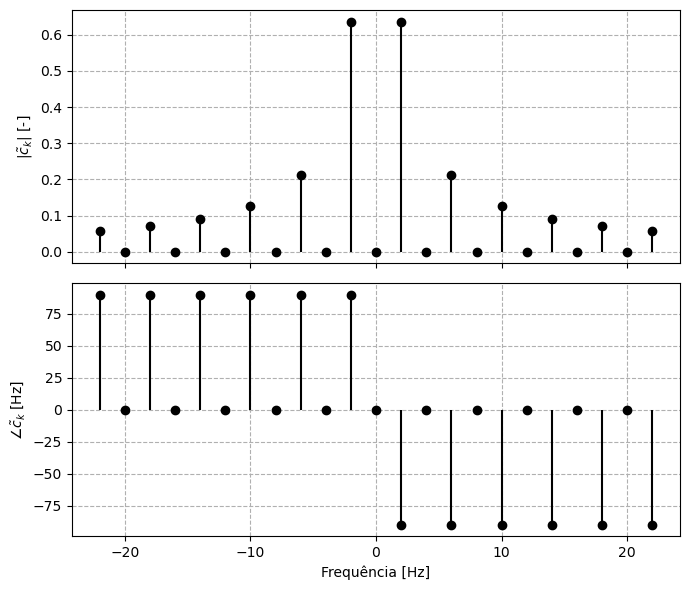

In [9]:
fig, axs = plt.subplots(2, 1, figsize = (7,6), sharex = True)
axs[0].stem(freq_vec, np.abs(ck), '-k', basefmt=" ")
axs[0].grid(linestyle = '--', which='both')
axs[0].set_ylabel(r'$|\tilde{c}_k|$ [-]')
axs[1].stem(freq_vec, np.rad2deg(np.angle(ck)), '-k', basefmt=" ")
axs[1].grid(linestyle = '--', which='both')
axs[1].set_ylabel(r'$\angle\tilde{c}_k$ [Hz]')
axs[1].set_xlabel('Frequência [Hz]')
plt.tight_layout()

### Reconstrução do sinal

Uma vez que uma série de componentes $\tilde{c}_k$ está computada, podemos reconstruir o sinal no tempo usando a Eq. (6). Claramente não somaremos infinitas componentes de frequência, uma vez que computamos uma versão truncada do espectro contendo as primeiras $N_k$ componentes de frequência (até uma frequência máxima).

Vamos plotar primeiro o sinal original e cada cosseno que o compõe. Note que o período da primeira harmônica é exatamente igual ao período fundamental do sinal. As harmônicas de ordem par possuem amplitude nula $(\tilde{c}_k = 0)$ e as harmônicas ímpares possuem exatamente 3, 5, 7, etc, ciclos dentro de um período fundamental do sinal.

Note também o que acontece quando reconstruímos o sinal com mais e mais componentes de frequência adicionados.

In [10]:
xt_mtx = np.zeros((len(k), len(t)), dtype = complex)
for jk in np.arange(0,len(k)):
    xt_mtx[jk,:] = ck[jk]*np.exp(1j*k[jk]*w1*t)
xt_recon = np.sum(xt_mtx, axis = 0)

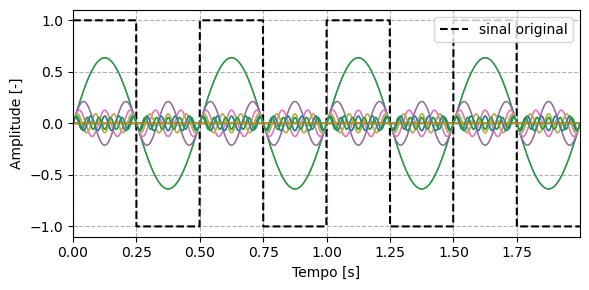

In [12]:
# Vamos plotar o sinal original e cada componente
plt.figure(figsize=(6,3))
plt.plot(t, xt, '--k', linewidth = 1.5, label = 'sinal original')
for jk in np.arange(0,len(k)):
    plt.plot(t, np.real(xt_mtx[jk,:]), linewidth = 1)
plt.legend(loc = 'upper right')
plt.grid(linestyle = '--', which='both')
plt.xlabel('Tempo [s]')
plt.ylabel('Amplitude [-]')
plt.xlim((0, t[-1]))
plt.tight_layout()

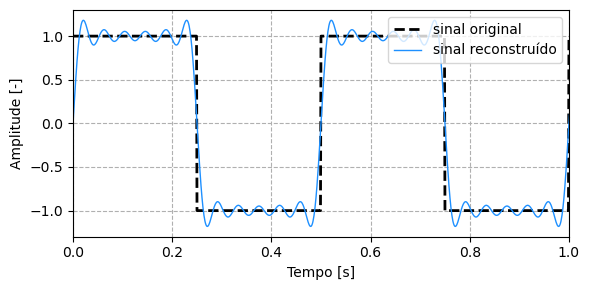

In [62]:
# Vamos plotar o sinal original e o reconstruído
plt.figure(figsize=(6,3))
plt.plot(t, xt, '--k', linewidth = 2, label = 'sinal original')
plt.plot(t, np.real(xt_recon), '-', color = 'dodgerblue',  linewidth = 1, label = 'sinal reconstruído')
plt.legend(loc = 'upper right')
plt.grid(linestyle = '--', which='both')
plt.xlabel('Tempo [s]')
plt.ylabel('Amplitude [-]')
plt.xlim((0, 1))
plt.tight_layout()

#### O que você nota?
<details>
  <summary><b>▶ Clique aqui para ver a resposta</b></summary>
  
  <br>
  
  ### Resposta
-  A reconstrução do sinal converge quando incluímos um número infinito de termos no somatório
-  Na prática, estamos tentando reconstruir $x(t)$ com um número finito de componentes de baixa frequência
-  Para um sinal com descontinuidades, como o do exemplo, é difícil fazer uma reconstrução perfeita sem muitos componentes de alta frequência

## 3. A transformada de Fourier

A transformada de Fourier (TF) é mais geral do que a série de Fourier e se aplica à classe dos sinais não periódicos (ou não necessariamente periódicos). Uma forma simples de chegar à TF, a partir da intuição da série de Fourier, é deixar que o período fundamental tenda ao infinito. Podemos pensar que toda a informação de um sinal periódico está contida em 1 período, $T_p$. Assim, a integração na Eq. (7) se dá ao longo de apenas um período. Chamemos

\begin{equation}
\tilde{c}_k = \frac{X(\text{j} k \omega_1)}{T_p},
\end{equation}

com 

\begin{equation}
X(\text{j} k \omega_1)= \int\limits_{-T_p/2}^{T_p/2} x_p(t)\text{e}^{-\text{j}k\omega_1 t}\text{d}t,
\end{equation}
em que $x_p(t)$ ainda é um sinal periódico. Então, da Eq. (6) temos

\begin{equation}
x_p(t) = \sum\limits_{k=-\infty}^{\infty} \frac{X(\text{j} k \omega_1)}{T_p}\text{e}^{\text{j}k\omega_1 t},
\end{equation}
e como $\omega_1 = \frac{2\pi}{T_p}$, podemos substituir o termo $\frac{1}{T_p}$ por $\frac{\omega_1}{2\pi}$, o que resulta em

\begin{equation}
x_p(t) = \frac{1}{2\pi}\sum\limits_{k=-\infty}^{\infty}X(\text{j} k \omega_1)\text{e}^{\text{j}k\omega_1 t} \omega_1.
\end{equation}

Até aqui, nós apenas rearranjamos os termos de maneira conveniente, mas nada efetivamente mudou. Nosso sinal continua periódico e o espectro ainda existe apenas para múltiplos inteiros de $\omega_1$. No entanto podemos deixar $T_p \rightarrow \infty$, o que resulta nos seguintes fatos:

- o sinal periódico tende a um sinal qualquer: $x_p(t) \rightarrow x(t)$;
- a frequência fundamental (ou o primeiro valor de frequência diferente de zero) será $\text{d}\omega = \lim\limits_{T_p \to \infty} \frac{2\pi}{T_p}$;
- consequentemente, o valor da $k$-ésima frequência será: $\omega = k\omega_1 = k\text{d}\omega$ (uma variável independente contínua);
- o somatório da Eq. (6) se tornará uma integral.

Assim, agora temos um sinal $x(t)$ não necessariamente periódico e um espectro que existe para qualquer valor contínuo de $\omega$, e portanto

\begin{equation}
x(t) = \frac{1}{2\pi}\int\limits_{-\infty}^{\infty}X(\text{j} \omega)\text{e}^{\text{j}\omega t} \text{d}\omega,
\tag{8}
\end{equation}

e 

\begin{equation}
X(\text{j} \omega) = \int\limits_{-\infty}^{\infty}x(t)\text{e}^{-\text{j}\omega t} \text{d}\omega.
\tag{9}
\end{equation}

O par formado pelas Eqs. (8) e (9) são conhecidos como:

- Transformada Inversa de Fourier: levando o sinal do domínio da frequência ([Hz] ou [1/s]) para o domínio do tempo ([s]);
- Transformada de Fourier: levando o sinal do domínio do tempo ([s]) para o domínio da frequência ([Hz] ou [1/s]).

Note alguns aspectos importantes. Primeiramente, o fenômeno em si não é alterado pela transformação de um domínio para outro. A única coisa realmente acontecendo é uma mudança de ponto de vista: você pode observar o fenômeno no domínio do tempo ou no domínio da frequência, e a única alteração será na sua variável independente. Note que esta se altera de [s] para [1/s] (o inverso). O teorema de Parseval nos ajuda a sedimentar tal intuição, nos informando que a energia total do sinal computada no domínio do tempo é igual a energia total do sinal computada no domínio da frequência. Tal teorema é dado por

\begin{equation}
\int\limits_{-\infty}^{\infty} |x(t)|^2 \text{d}t = \frac{1}{2\pi} \int\limits_{-\infty}^{\infty} | X(\text{j} \omega)|^2\text{d}\omega.
\tag{10}
\end{equation}

Note também que a Eq. (9) é um produto interno, efetivamente calculando a projeção do fenômeno no domínio do tempo na direção da função $\text{e}^{\text{j}\omega t}=\cos(\omega t) +\text{j}\sin(\omega t)$. E como senos e cossenos de frequências diferentes são funções ortogonais, efetivamente o produto interno computa quanta energia de $x(t)$ está contida exatamente na frequência angular $\omega$.

Por fim, note que $X(\text{j} \omega) \in \mathbb{C}$ (espectro complexo com magnitude e fase). A opção de grafia da função contínua de $\omega$ reflete este fato.

## A. Pares importantes

Podemos agora calcular e plotar alguns pares importantes de $x(t)$ e $X(\text{j}\omega)$. Usaremos a seguinte notação

\begin{equation}
x(t) \xleftrightarrow{\mathcal{F}} X(\text{j} \omega)
\end{equation}

#### 1. exponencial complexa

Um dos sinais mais fundamentais é a exponencial complexa $x(t) = \text{e}^{\text{j}\omega_0 t}$. Tal sinal possui apenas uma componente de frequência não nula sobre $\omega_0$. Logo o par de TF é dado por 


\begin{equation}
\text{e}^{\text{j}\omega_0 t} \xleftrightarrow{\mathcal{F}} 2\pi \delta(\omega-\omega_0).
\end{equation}

Note que $\delta(\cdot)$ é a função delta de Dirac, $\omega_0$ é a frequência angular do sinal e $\omega$ é a variável independente no domínio da frequência. Vamos plotar esse fenômeno em ambos os domínios.

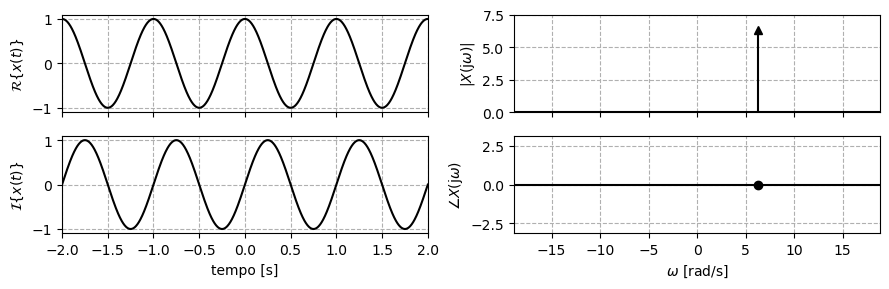

In [9]:
f_0 = 1
omega_0 = 2*np.pi*f_0
time = np.linspace(-2, 2, 1000)
xt = np.exp(1j*omega_0*time)

mosaic = [['a', 'c'],['b', 'd']]
fig, axs = plt.subplot_mosaic(mosaic, figsize=(9, 3))
axs['a'].sharex(axs['b'])
axs['a'].plot(time, np.real(xt), 'k', linewidth = 1.5)
axs['a'].grid(linestyle = '--')
axs['a'].set_xlim((time[0], time[-1]))
axs['a'].set_ylim((-1.1, 1.1))
axs['a'].set_ylabel(r"$\mathcal{R}\left\{x(t)\right\}$")
axs['a'].tick_params(labelbottom=False) 

axs['b'].plot(time, np.imag(xt), 'k', linewidth = 1.5)
axs['b'].grid(linestyle = '--')
axs['b'].set_xlim((time[0], time[-1]))
axs['b'].set_ylim((-1.1, 1.1))
axs['b'].set_ylabel(r"$\mathcal{I}\left\{x(t)\right\}$")
axs['b'].set_xlabel(r'tempo [s]')

axs['c'].sharex(axs['d'])
markerline, stemlines, baseline = axs['c'].stem(2*np.pi*f_0, 2*np.pi, 'k', markerfmt='^k', basefmt=" ")
axs['c'].axhline(0, color='k', linewidth=1.5) 
axs['c'].set_xlim((-3*2*np.pi*f_0, 3*2*np.pi*f_0))
axs['c'].set_ylim((0, 7.5))
axs['c'].grid(linestyle = '--')
axs['c'].set_ylabel(r"$|X(\text{j}\omega)|$")
axs['c'].tick_params(labelbottom=False) 

markerline, stemlines, baseline = axs['d'].stem(2*np.pi*f_0, 0, 'k', basefmt=" ")
axs['d'].axhline(0, color='k', linewidth=1.5) 
axs['d'].set_xlim((-3*2*np.pi*f_0, 3*2*np.pi*f_0))
axs['d'].set_ylim((-np.pi, np.pi))
axs['d'].grid(linestyle = '--')
axs['d'].set_ylabel(r"$\angle X(\text{j}\omega)$")
axs['d'].set_xlabel(r'$\omega$ [rad/s]')
plt.tight_layout()

#### 2. senos e cossenos

Senos e cossenos estão fundamentalmente relacionados ao espectro da exponencial complexa, pois podem ser representados pela expansão de Euler. A diferença fundamental é que tais funções são $\in \mathbb{R}$. Para um cosseno de frequência $\omega_0 = 2\pi f_0$, temos  $x(t) = \cos(\omega_0 t) = \frac{\text{e}^{\text{j}\omega_0 t}+\text{e}^{-\text{j}\omega_0 t}}{2}$. Logo, teremos

\begin{equation}
\cos(\omega_0 t) \xleftrightarrow{\mathcal{F}} \frac{1}{2}\mathcal{F}\left\{\text{e}^{\text{j}\omega_0 t}\right\} + \frac{1}{2}\mathcal{F}\left\{\text{e}^{-\text{j}\omega_0 t}\right\},
\end{equation}
ou 

\begin{equation}
\cos(\omega_0 t) \xleftrightarrow{\mathcal{F}} \pi \delta(\omega-\omega_0) + \pi \delta(\omega+\omega_0).
\end{equation}

Note que o espectro do $\cos(\omega_0 t)$ possui duas componentes de frequência em $\pm \omega_0$ com magnitude $\pi$ e fase nula.

Já, para um seno de frequência $\omega_0 = 2\pi f_0$, temos  $x(t) = \sin(\omega_0 t) = \frac{\text{e}^{\text{j}\omega_0 t}-\text{e}^{-\text{j}\omega_0 t}}{2\text{j}}$. Logo, teremos

\begin{equation}
\sin(\omega_0 t) \xleftrightarrow{\mathcal{F}} \frac{1}{2\text{j}}\mathcal{F}\left\{\text{e}^{\text{j}\omega_0 t}\right\} - \frac{1}{2\text{j}}\mathcal{F}\left\{\text{e}^{-\text{j}\omega_0 t}\right\},
\end{equation}
ou 

\begin{equation}
\sin(\omega_0 t) \xleftrightarrow{\mathcal{F}} \frac{\pi}{\text{j}} \delta(\omega-\omega_0) - \frac{\pi}{\text{j}} \delta(\omega+\omega_0).
\end{equation}

Note que o espectro do $\sin(\omega_0 t)$ possui duas componentes de frequência em $\pm \omega_0$ com magnitude $\pi$ e fase $\mp \pi/2$. Vamos plotar tais fenômenos.


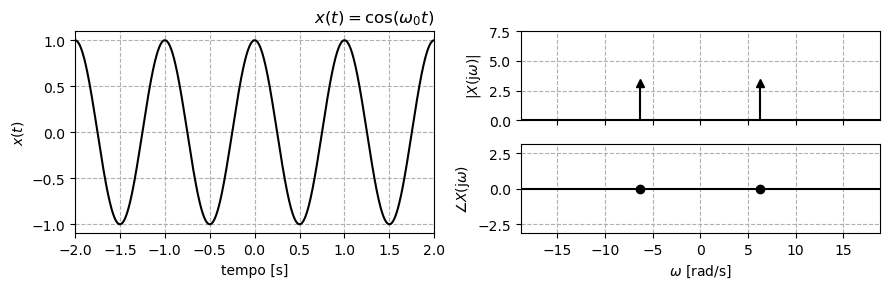

In [10]:
f_0 = 1
omega_0 = 2*np.pi*f_0
time = np.linspace(-2, 2, 1000)
xt = np.cos(omega_0*time)

mosaic = [['a', 'c'],['a', 'd']]

fig, axs = plt.subplot_mosaic(mosaic, figsize=(9, 3))
axs['a'].plot(time, xt, 'k', linewidth = 1.5)
axs['a'].grid(linestyle = '--')
axs['a'].set_xlim((time[0], time[-1]))
axs['a'].set_ylim((-1.1, 1.1))
axs['a'].set_ylabel(r"$x(t)$")
axs['a'].set_xlabel(r'tempo [s]')
axs['a'].set_title(r'$x(t) = \cos(\omega_0 t)$', loc = 'right')

axs['c'].sharex(axs['d'])
markerline, stemlines, baseline = axs['c'].stem([-2*np.pi*f_0, 2*np.pi*f_0], [np.pi, np.pi], 'k', markerfmt='^k', basefmt=" ")
axs['c'].axhline(0, color='k', linewidth=1.5) 
axs['c'].set_xlim((-3*2*np.pi*f_0, 3*2*np.pi*f_0))
axs['c'].set_ylim((0, 7.5))
axs['c'].grid(linestyle = '--')
axs['c'].set_ylabel(r"$|X(\text{j}\omega)|$")
axs['c'].tick_params(labelbottom=False) 

markerline, stemlines, baseline = axs['d'].stem([-2*np.pi*f_0, 2*np.pi*f_0], [-0, 0], 'k', basefmt=" ")
axs['d'].axhline(0, color='k', linewidth=1.5) 
axs['d'].set_xlim((-3*2*np.pi*f_0, 3*2*np.pi*f_0))
axs['d'].set_ylim((-np.pi, np.pi))
axs['d'].grid(linestyle = '--')
axs['d'].set_ylabel(r"$\angle X(\text{j}\omega)$")
axs['d'].set_xlabel(r'$\omega$ [rad/s]')
plt.tight_layout()

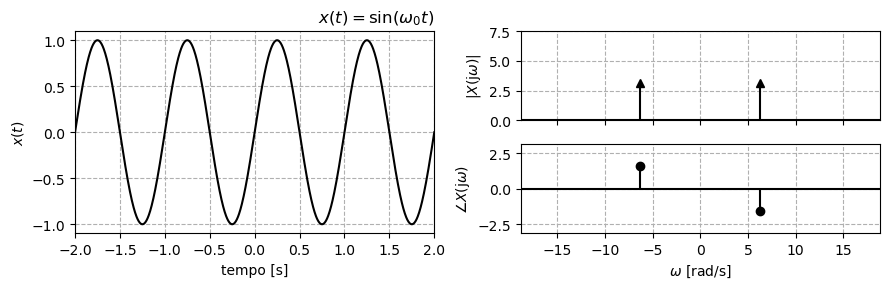

In [11]:
f_0 = 1
omega_0 = 2*np.pi*f_0
time = np.linspace(-2, 2, 1000)
xt = np.sin(omega_0*time)

mosaic = [['a', 'c'],['a', 'd']]

fig, axs = plt.subplot_mosaic(mosaic, figsize=(9, 3))
axs['a'].plot(time, xt, 'k', linewidth = 1.5)
axs['a'].grid(linestyle = '--')
axs['a'].set_xlim((time[0], time[-1]))
axs['a'].set_ylim((-1.1, 1.1))
axs['a'].set_ylabel(r"$x(t)$")
axs['a'].set_xlabel(r'tempo [s]')
axs['a'].set_title(r'$x(t) = \sin(\omega_0 t)$', loc = 'right')

axs['c'].sharex(axs['d'])
markerline, stemlines, baseline = axs['c'].stem([-2*np.pi*f_0, 2*np.pi*f_0], [np.pi, np.pi], 'k', markerfmt='^k', basefmt=" ")
axs['c'].axhline(0, color='k', linewidth=1.5) 
axs['c'].set_xlim((-3*2*np.pi*f_0, 3*2*np.pi*f_0))
axs['c'].set_ylim((0, 7.5))
axs['c'].grid(linestyle = '--')
axs['c'].set_ylabel(r"$|X(\text{j}\omega)|$")
axs['c'].tick_params(labelbottom=False) 

markerline, stemlines, baseline = axs['d'].stem([-2*np.pi*f_0, 2*np.pi*f_0], [np.pi/2, -np.pi/2], 'k', basefmt=" ")
axs['d'].axhline(0, color='k', linewidth=1.5) 
axs['d'].set_xlim((-3*2*np.pi*f_0, 3*2*np.pi*f_0))
axs['d'].set_ylim((-np.pi, np.pi))
axs['d'].grid(linestyle = '--')
axs['d'].set_ylabel(r"$\angle X(\text{j}\omega)$")
axs['d'].set_xlabel(r'$\omega$ [rad/s]')
plt.tight_layout()

#### 3. delta de Dirac

Um outro importante sinal é o delta de Dirac, $\delta(t)$. Uma importante propriedade da função é

\begin{equation}
\int\limits_{-\infty}^{\infty} \delta(t)\text{d}t = 1,
\end{equation}
o que significa que toda a energia do sinal está concentrada no instante $t=0$. Outra importante propriedade é 

\begin{equation}
\int\limits_{-\infty}^{\infty} \delta(t-t_0)f(t)\text{d}t = f(t_0),
\end{equation}
em que $f(t)$ é uma função qualquer. Assim, a transformada de Fourier de $\delta(t)$ é

\begin{equation}
\Delta(\text{j}\omega) = \int\limits_{-\infty}^{\infty} \delta(t)\text{e}^{-\text{j}\omega t}\text{d}t = \text{e}^{-\text{j}\omega 0} = 1,
\end{equation}

ou seja

\begin{equation}
\delta(t) \xleftrightarrow{\mathcal{F}} 1.
\end{equation}

Note que o espectro de $\delta(t)$ é uma constante em função da frequência, possuindo magnitude unitária e fase nula. Vamos plotar este fenômeno.

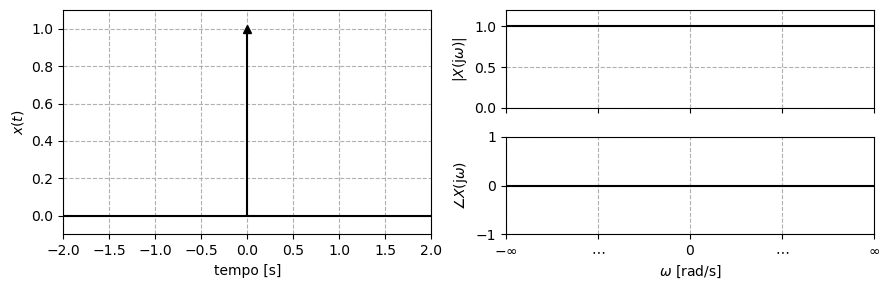

In [12]:
mosaic = [['a', 'c'],['a', 'd']]
fig, axs = plt.subplot_mosaic(mosaic, figsize=(9, 3))
markerline, stemlines, baseline = axs['a'].stem(0, 1, 'k', markerfmt='^k', basefmt=" ")
axs['a'].axhline(0, color='k', linewidth=1.5) 
axs['a'].grid(linestyle = '--')
axs['a'].set_xlim((time[0], time[-1]))
axs['a'].set_ylim((-0.1, 1.1))
axs['a'].set_ylabel(r"$x(t)$")
axs['a'].set_xlabel(r'tempo [s]')
#axs['a'].set_title(r'$x(t) = \sin(\omega_0 t)$', loc = 'right')

omega = np.linspace(-20, 20, 100)
axs['c'].sharex(axs['d'])
axs['c'].plot(omega, np.ones(len(omega)), 'k')
axs['c'].set_xlim((omega[0], omega[-1]))
axs['c'].set_ylim((0, 1.2))
axs['c'].grid(linestyle = '--')
axs['c'].set_ylabel(r"$|X(\text{j}\omega)|$")
axs['c'].tick_params(labelbottom=False) 

axs['d'].plot(omega, np.zeros(len(omega)), 'k')
axs['c'].set_xlim((omega[0], omega[-1]))
axs['d'].set_ylim((-1, 1))
axs['d'].grid(linestyle = '--')
axs['d'].set_xticks([-20,-10,0,10,20])
axs['d'].set_xticklabels([r"$-\infty$", r"$\cdots$", r"0", r"$\cdots$", r"$\infty$"])
axs['d'].set_ylabel(r"$\angle X(\text{j}\omega)$")
axs['d'].set_xlabel(r'$\omega$ [rad/s]')
plt.tight_layout()

#### 4. sinal constante no tempo

Um sinal constante com o tempo é dado por $x(t) = 1$. Neste caso o espectro é
\begin{equation}
X(\text{j}\omega) = \int\limits_{-\infty}^{\infty} 1 \ \text{e}^{-\text{j}\omega t}\text{d}t = \delta(\omega),
\end{equation}

ou seja

\begin{equation}
1 \xleftrightarrow{\mathcal{F}} \delta(\omega).
\end{equation}

Note que o espectro do sinal constante é $\delta(\omega)$, o que provê um contraponto interessante à \delta(t) \xleftrightarrow{\mathcal{F}} 1. Vamos plotar este fenômeno.

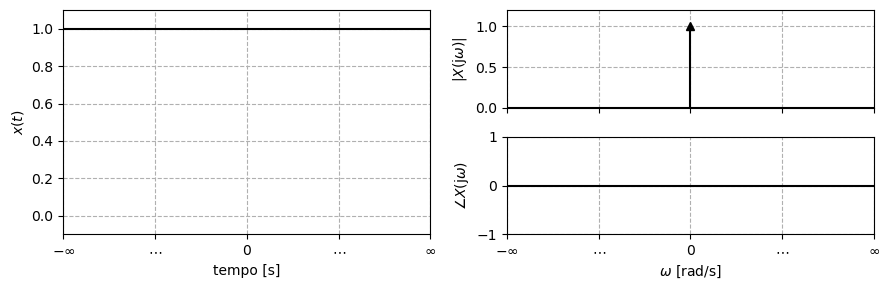

In [14]:
time = np.linspace(-20, 20, 1000)
mosaic = [['a', 'c'],['a', 'd']]
fig, axs = plt.subplot_mosaic(mosaic, figsize=(9, 3))
axs['a'].plot(time, np.ones(len(time)), 'k')
axs['a'].grid(linestyle = '--')
axs['a'].set_xlim((time[0], time[-1]))
axs['a'].set_xticks([-20,-10,0,10,20])
axs['a'].set_xticklabels([r"$-\infty$", r"$\cdots$", r"0", r"$\cdots$", r"$\infty$"])
axs['a'].set_ylim((-0.1, 1.1))
axs['a'].set_ylabel(r"$x(t)$")
axs['a'].set_xlabel(r'tempo [s]')
#axs['a'].set_title(r'$x(t) = \sin(\omega_0 t)$', loc = 'right')

#omega = np.linspace(-20, 20, 100)
axs['c'].sharex(axs['d'])
markerline, stemlines, baseline = axs['c'].stem(0, 1, 'k', markerfmt='^k', basefmt=" ")
axs['c'].axhline(0, color='k', linewidth=1.5) 
axs['c'].set_xlim((omega[0], omega[-1]))
axs['c'].set_ylim((0, 1.2))
axs['c'].grid(linestyle = '--')
axs['c'].set_ylabel(r"$|X(\text{j}\omega)|$")
axs['c'].tick_params(labelbottom=False) 

axs['d'].plot(omega, np.zeros(len(omega)), 'k')
axs['c'].set_xlim((omega[0], omega[-1]))
axs['d'].set_ylim((-1, 1))
axs['d'].grid(linestyle = '--')
axs['d'].set_xticks([-20,-10,0,10,20])
axs['d'].set_xticklabels([r"$-\infty$", r"$\cdots$", r"0", r"$\cdots$", r"$\infty$"])
axs['d'].set_ylabel(r"$\angle X(\text{j}\omega)$")
axs['d'].set_xlabel(r'$\omega$ [rad/s]')
plt.tight_layout()

#### 5. exponencial decrescente

Podemos estender a intuição construída a partir do delta de Dirac e seu espectro ($\delta(t) \xleftrightarrow{\mathcal{F}} 1$) ao investigar o seguinte sinal

\begin{equation}
x(t) = \text{e}^{-a t}u(t),
\end{equation}
em que $a \in \mathbb{R}$, $a>0$, e $u(t)$ representa a função degrau, dada por

\begin{equation}
u(t) = 
\begin{cases}
1 \ \ \ \text{para} \ \ \ t \geq 0 \\
0 \ \ \ \text{para} \ \ \ t < 0
\end{cases}.
\end{equation}

Assim, a transformada de Fourier é

\begin{equation}
X(\text{j}\omega) = \int\limits_{-\infty}^{\infty} \text{e}^{-a t}u(t)\text{e}^{-\text{j}\omega t}\text{d}t = \int\limits_{0}^{\infty} \text{e}^{-a t}\text{e}^{-\text{j}\omega t}\text{d}t = \int\limits_{0}^{\infty} \text{e}^{-(a+\text{j}\omega) t}\text{d}t = \frac{1}{a+\text{j}\omega},
\end{equation}

ou seja

\begin{equation}
X(\text{j}\omega) \xleftrightarrow{\mathcal{F}} \frac{1}{a+\text{j}\omega}.
\end{equation}

Vamos plotar este fenômeno para alguns valores de $a$ e observar o que ocorre.

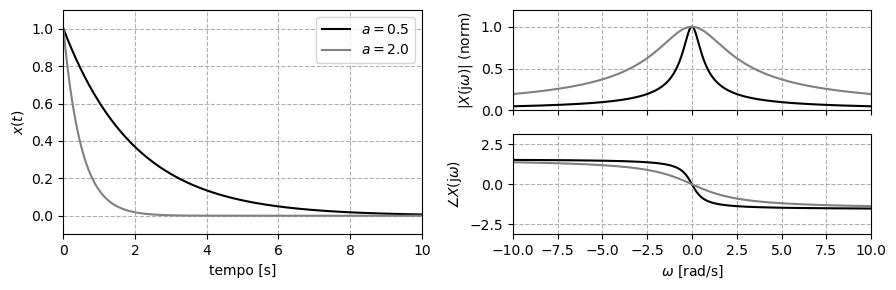

In [15]:
a_l = [0.5, 2]
colors = ['k', 'grey']
time = np.linspace(0, 10, 1000)
omega = np.linspace(-10,10,1000)
xt_l = []
Xjw_l = []
for a in a_l:
    xt_l.append(np.exp(-a*time))
    Xjw_l.append(1/(a+1j*omega))

mosaic = [['a', 'c'],['a', 'd']]
fig, axs = plt.subplot_mosaic(mosaic, figsize=(9, 3))
for j in range(len(a_l)):
    axs['a'].plot(time, xt_l[j], color = colors[j], linewidth = 1.5, label = r"$a = {:.1f}$".format(a_l[j]))
axs['a'].legend()
axs['a'].grid(linestyle = '--')
axs['a'].set_xlim((time[0], time[-1]))
axs['a'].set_ylim((-0.1, 1.1))
axs['a'].set_ylabel(r"$x(t)$")
axs['a'].set_xlabel(r'tempo [s]')
#axs['a'].set_title(r'$x(t) = \sin(\omega_0 t)$', loc = 'right')

axs['c'].sharex(axs['d'])
for j in range(len(a_l)):
    axs['c'].plot(omega, np.abs(Xjw_l[j])/np.amax(np.abs(Xjw_l[j])), color = colors[j], linewidth = 1.5, 
                  label = r"$a = {:.1f}$".format(a_l[j]))
axs['c'].set_xlim((omega[0], omega[-1]))
axs['c'].set_ylim((0, 1.2))
axs['c'].grid(linestyle = '--')
axs['c'].set_ylabel(r"$|X(\text{j}\omega)|$ (norm)")
axs['c'].tick_params(labelbottom=False) 

for j in range(len(a_l)):
    axs['d'].plot(omega, np.angle(Xjw_l[j]), color = colors[j], linewidth = 1.5, 
                  label = r"$a = {:.1f}$".format(a_l[j]))
axs['d'].set_xlim((omega[0], omega[-1]))
axs['d'].set_ylim((-np.pi, np.pi))
axs['d'].grid(linestyle = '--')
axs['d'].set_ylabel(r"$\angle X(\text{j}\omega)$")
axs['d'].set_xlabel(r'$\omega$ [rad/s]')
plt.tight_layout()

#### O que você nota?
<details>
  <summary><b>▶ Clique aqui para ver a resposta</b></summary>
  
  <br>
  
  ### Resposta
-  ao aumentar $a$, o sinal decai mais rapidamente (se aproxima mais de um impulso perfeito)
-  consequentemente, o espectro tende a ficar mais e mais plano.
-  se $a$ diminuir demais, $x(t)$ tende a ser um sinal constante, e consequentemente, seu espectro tende a $\delta(\omega)$.

#### 6. janela temporal

Um importante sinal é chamado de janela temporal (um sinal constante dentro de um intervalo de tempo e nulo fora do intervalo). Matematicamente, o sinal é definido por

\begin{equation}
x(t) = 
\begin{cases}
1 \ \ \ \text{para} \ \ \ |t| \leq T_p/2 \\
0 \ \ \ \text{para} \ \ \ |t| > T_p/2
\end{cases}.
\end{equation}

Sua transformada de Fourier é

\begin{equation}
X(\text{j}\omega) = \int\limits_{-T_p/2}^{T_p/2} \text{e}^{-\text{j}\omega t}\text{d}t = \frac{-1}{\text{j}\omega}\text{e}^{-\text{j}\omega t}\biggr|_{-T_p/2}^{T_p/2} = \frac{-1}{\text{j}\omega}\left[\text{e}^{-\text{j}\omega T_p/2}-\text{e}^{\text{j}\omega T_p/2}\right] = \frac{2}{\omega} \frac{\text{e}^{\text{j}\omega T_p/2}-\text{e}^{\text{j}\omega T_p/2}}{2\text{j}}=\frac{2}{\omega}\sin(\omega T_p/2)\frac{T_p/2}{T_p/2},
\end{equation}

\begin{equation}
X(\text{j}\omega) = T_p \frac{\sin(\omega T_p/2)}{\omega T_p/2} = T_p \ \text{sinc}(\omega T_p/2),
\end{equation}

ou seja

\begin{equation}
X(\text{j}\omega) \xleftrightarrow{\mathcal{F}} T_p \ \text{sinc}(\omega T_p/2).
\end{equation}

A importância deste sinal reside no fato de que ele representa um processo de aquisição de dados no tempo (ou no espaço), já que qualquer medição real vai se dar num intervalo de tempo finito (ou cobrir uma porção finita do espaço). Vamos plotar este fenômeno para alguns valores de $T_p$.

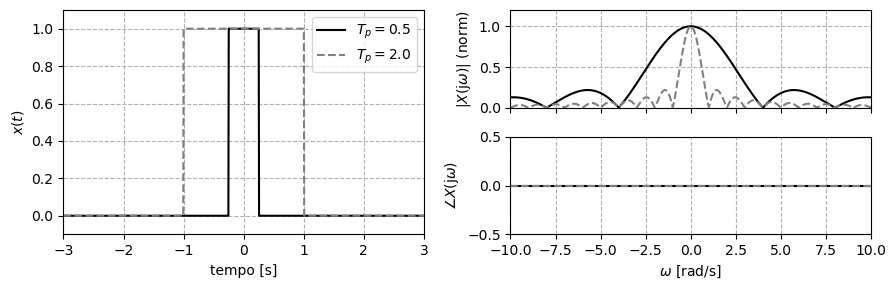

In [16]:
Tp_l = [0.5, 2]
colors = ['k', 'grey']
ls = ['-', '--']
time = np.linspace(-3, 3, 1000)
omega = np.linspace(-10,10,1000)
xt_l = []
Xjw_l = []
for Tp in Tp_l:
    xt = np.zeros(len(time))
    indices = np.where((time >= -Tp/2) & (time <= Tp/2))[0]
    xt[indices] = 1
    xt_l.append(xt)
    Xjw_l.append(Tp*np.sinc(omega*Tp/2))

mosaic = [['a', 'c'],['a', 'd']]
fig, axs = plt.subplot_mosaic(mosaic, figsize=(9, 3))
for j in range(len(Tp_l)):
    axs['a'].plot(time, xt_l[j], color = colors[j], linewidth = 1.5, linestyle = ls[j], label = r"$T_p = {:.1f}$".format(Tp_l[j]))
axs['a'].legend()
axs['a'].grid(linestyle = '--')
axs['a'].set_xlim((time[0], time[-1]))
axs['a'].set_ylim((-0.1, 1.1))
axs['a'].set_ylabel(r"$x(t)$")
axs['a'].set_xlabel(r'tempo [s]')
#axs['a'].set_title(r'$x(t) = \sin(\omega_0 t)$', loc = 'right')

axs['c'].sharex(axs['d'])
for j in range(len(Tp_l)):
    axs['c'].plot(omega, np.abs(Xjw_l[j])/np.amax(np.abs(Xjw_l[j])), color = colors[j], linestyle = ls[j], linewidth = 1.5, 
                  label = r"$T_p = {:.1f}$".format(Tp_l[j]))
axs['c'].set_xlim((omega[0], omega[-1]))
axs['c'].set_ylim((0, 1.2))
axs['c'].grid(linestyle = '--')
axs['c'].set_ylabel(r"$|X(\text{j}\omega)|$ (norm)")
axs['c'].tick_params(labelbottom=False) 

for j in range(len(Tp_l)):
    axs['d'].plot(omega, np.zeros(len(omega)), color = colors[j], linestyle = ls[j], linewidth = 1.5, 
                  label = r"$T_p = {:.1f}$".format(Tp_l[j]))
axs['d'].set_xlim((omega[0], omega[-1]))
axs['d'].set_ylim((-0.5, 0.5))
axs['d'].grid(linestyle = '--')
axs['d'].set_ylabel(r"$\angle X(\text{j}\omega)$")
axs['d'].set_xlabel(r'$\omega$ [rad/s]')
plt.tight_layout()

#### O que você nota?
<details>
  <summary><b>▶ Clique aqui para ver a resposta</b></summary>
  
  <br>
  
  ### Resposta
-  à medida que $T_p$ aumenta, a janela temporal tende a um sinal constante, se seu espectro tende à $\delta(\omega)$.